# Hyper Technology · Physics-Informed Machine Learning
## EP01 — Can AI Really Understand Physics?
**Unit 01 · The Big Picture | Conceptual scientific lab | CPU only**

### 1. Goal and learning objectives
**Can a field match every sensor, the starting temperature, and the endpoint temperatures — yet violate the heat equation? Yes.** This lab builds a controlled counterexample and tests it.

By the end, you will be able to:
1. Read a temperature field as a function of position and time.
2. Distinguish synthetic observations from independent physical checks.
3. Explain why fitting a few observations does not establish physical consistency everywhere.
4. Interpret a differential-equation residual without training a model.

**What this notebook contains:** an analytical reference, synthetic observations, and an analytically constructed counterexample. **There is no trained neural network here.** The first full PINN training lesson is Episode 11 in the approved 70-episode curriculum v1.1.

**Run:** In Google Colab, choose **Runtime → Run all**, using a CPU runtime. No uploads, datasets, credentials, or package installations are needed after opening this notebook. All seven figures and compact numerical data are generated by the cells below. Outputs are saved relative to the current notebook working directory.

**Relation to the episode:** the physical benchmark is unchanged. This lab deliberately uses five *interior* sensors and a time-dependent sine counterexample. The episode's illustrative comparison uses different positions (including the endpoints) and a constructed curve. This is an extension of the episode's idea, not a reproduction of a trained-model experiment.

### 2. The physical problem
A rod has length $L=0.10\,\mathrm{m}$. Position $x$ runs along the rod and physical time $t$ runs from 0 to 20 seconds. Temperature is $T(x,t)$ in degrees Celsius.

The governing equation is
$$\frac{\partial T}{\partial t}=\alpha\frac{\partial^2T}{\partial x^2},
\qquad \alpha=10^{-4}\,\mathrm{m^2/s}.$$
The left side describes change with time; the right side describes how spatial curvature drives that change. Here $\alpha$ is **thermal diffusivity**, not thermal conductivity.

For a temperature *difference*, one degree Celsius equals one kelvin. Thus both sides have units of $\mathrm{K/s}$, equivalently $^\circ\mathrm{C/s}$ for this calculation. A constant Celsius offset disappears under differentiation.

### 3. Assumptions, starting state, and boundaries
We assume one-dimensional heat conduction in a homogeneous rod with constant diffusivity, no internal heat source, and insulated lateral surfaces. The ends are connected to ideal temperature reservoirs held at $20^\circ\mathrm{C}$; heat can leave through those ends.

The initial condition is **not a uniformly hot rod**:
$$T(x,0)=20+60\sin(\pi x/L).$$
Only the midpoint starts at $80^\circ\mathrm{C}$; the endpoints start at $20^\circ\mathrm{C}$. For all times,
$$T(0,t)=T(L,t)=20^\circ\mathrm{C}.$$

The equation, domain, assumptions, initial condition, and boundary conditions define the reference problem. A law alone does not specify this entire problem.

### 4. Setup and reproducibility
NumPy performs the calculations. Matplotlib draws the computed values. Everything else below comes from Python's standard library or the notebook display system. No random data are used.

Each export is one **3840 × 2160 PNG**. Inline notebook displays use the same figure at a practical reading size. Rerunning the notebook updates only its own generated `figures/`, `data/`, and `verification_report.json` files.

In [1]:
from pathlib import Path
import sys, json, platform, hashlib
from datetime import datetime, timezone
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'matplotlib': matplotlib.__version__}
print('Runtime versions:', json.dumps(VERSIONS))
print('Deterministic calculation · CPU · no external input files')

ROOT = Path.cwd()
FIGURES = ROOT / 'figures'
DATA = ROOT / 'data'
FIGURES.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

L_M = 0.10
ALPHA_M2_PER_S = 1e-4
BASE_C = 20.0
INITIAL_AMPLITUDE_C = 60.0
COUNTEREXAMPLE_AMPLITUDE_C = 10.0
TAU_C_S = 5.0
END_S = 20.0
MODE_1_PER_M = np.pi / L_M
DECAY_PER_S = ALPHA_M2_PER_S * MODE_1_PER_M**2
MODE_6_PER_M = 6.0 * np.pi / L_M

CYAN, AMBER, VIOLET = '#7BD9EC', '#FFD08A', '#B9A1FF'
BG, WHITE = '#080B0E', '#FFFFFF'
THERMAL = LinearSegmentedColormap.from_list('HT_temperature',
    ['#16486A', '#258D96', '#7FB49B', '#DEC583', '#F09B62'])
SIGNED = LinearSegmentedColormap.from_list('HT_signed',
    [VIOLET, '#10161C', AMBER])
plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'text.color': WHITE, 'axes.labelcolor': WHITE, 'axes.edgecolor': WHITE,
    'xtick.color': WHITE, 'ytick.color': WHITE, 'font.family': 'DejaVu Sans',
    'font.size': 19, 'axes.titlesize': 25, 'axes.labelsize': 22,
    'xtick.labelsize': 18, 'ytick.labelsize': 18, 'legend.fontsize': 17,
    'axes.linewidth': 1.4, 'lines.linewidth': 3.0, 'text.usetex': False,
    'figure.dpi': 100, 'savefig.dpi': 240, 'path.simplify': False,
})
FIGURE_MANIFEST = []

def style_axis(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.16, color=WHITE)
    ax.set_axisbelow(True)
    ax.tick_params(length=6, pad=10)
    ax.xaxis.labelpad = 16
    ax.yaxis.labelpad = 16

def finish_figure(fig, filename, caption):
    path = FIGURES / filename
    # Fixed canvas: do not use bbox_inches='tight', which changes pixel size.
    fig.savefig(path, dpi=240)
    FIGURE_MANIFEST.append({'file': 'figures/' + filename,
                            'pixels': [3840, 2160], 'caption': caption})
    plt.show()
    plt.close(fig)

Runtime versions: {"python": "3.12.14", "numpy": "2.5.2", "matplotlib": "3.11.1"}
Deterministic calculation · CPU · no external input files


### 5. Implement the analytical solution
For this particular starting profile, the exact solution is
$$T_{\mathrm{exact}}(x,t)=20+60\sin(\pi x/L)e^{-\beta t},
\qquad \beta=\alpha\pi^2/L^2.$$
The sinusoidal shape stays the same while its amplitude decays. We implement the formula directly; we are not solving the equation with a neural network or a numerical time-stepping method.

The array convention throughout this notebook is **`field[time_index, position_index]`**. Both axes contain their endpoints.

In [2]:
def exact_temperature_C(x_m, t_s):
    return (BASE_C + INITIAL_AMPLITUDE_C * np.sin(MODE_1_PER_M * np.asarray(x_m))
            * np.exp(-DECAY_PER_S * np.asarray(t_s)))

x_m = np.linspace(0.0, L_M, 1201)
t_s = np.linspace(0.0, END_S, 201)
X_M, TIME_S = np.meshgrid(x_m, t_s, indexing='xy')
EXACT_C = exact_temperature_C(X_M, TIME_S)
assert EXACT_C.shape == (t_s.size, x_m.size)
assert np.all(np.isfinite(EXACT_C))
print(f'Decay rate beta = {DECAY_PER_S:.8f} s^-1')
print(f'Midpoint at 0 s:  {exact_temperature_C(L_M / 2, 0):.4f} °C')
print(f'Midpoint at 5 s:  {exact_temperature_C(L_M / 2, 5):.4f} °C')
print(f'Midpoint at 20 s: {exact_temperature_C(L_M / 2, 20):.4f} °C')

Decay rate beta = 0.09869604 s^-1
Midpoint at 0 s:  80.0000 °C
Midpoint at 5 s:  56.6299 °C
Midpoint at 20 s: 28.3347 °C


### 6. Watch the reference field evolve
First compare snapshots along the rod, then view all positions and times together. Colors represent actual computed temperatures with fixed limits of $20$ to $80^\circ\mathrm{C}$. At any finite time in this example, the interior remains above $20^\circ\mathrm{C}$; it approaches that value as time continues.

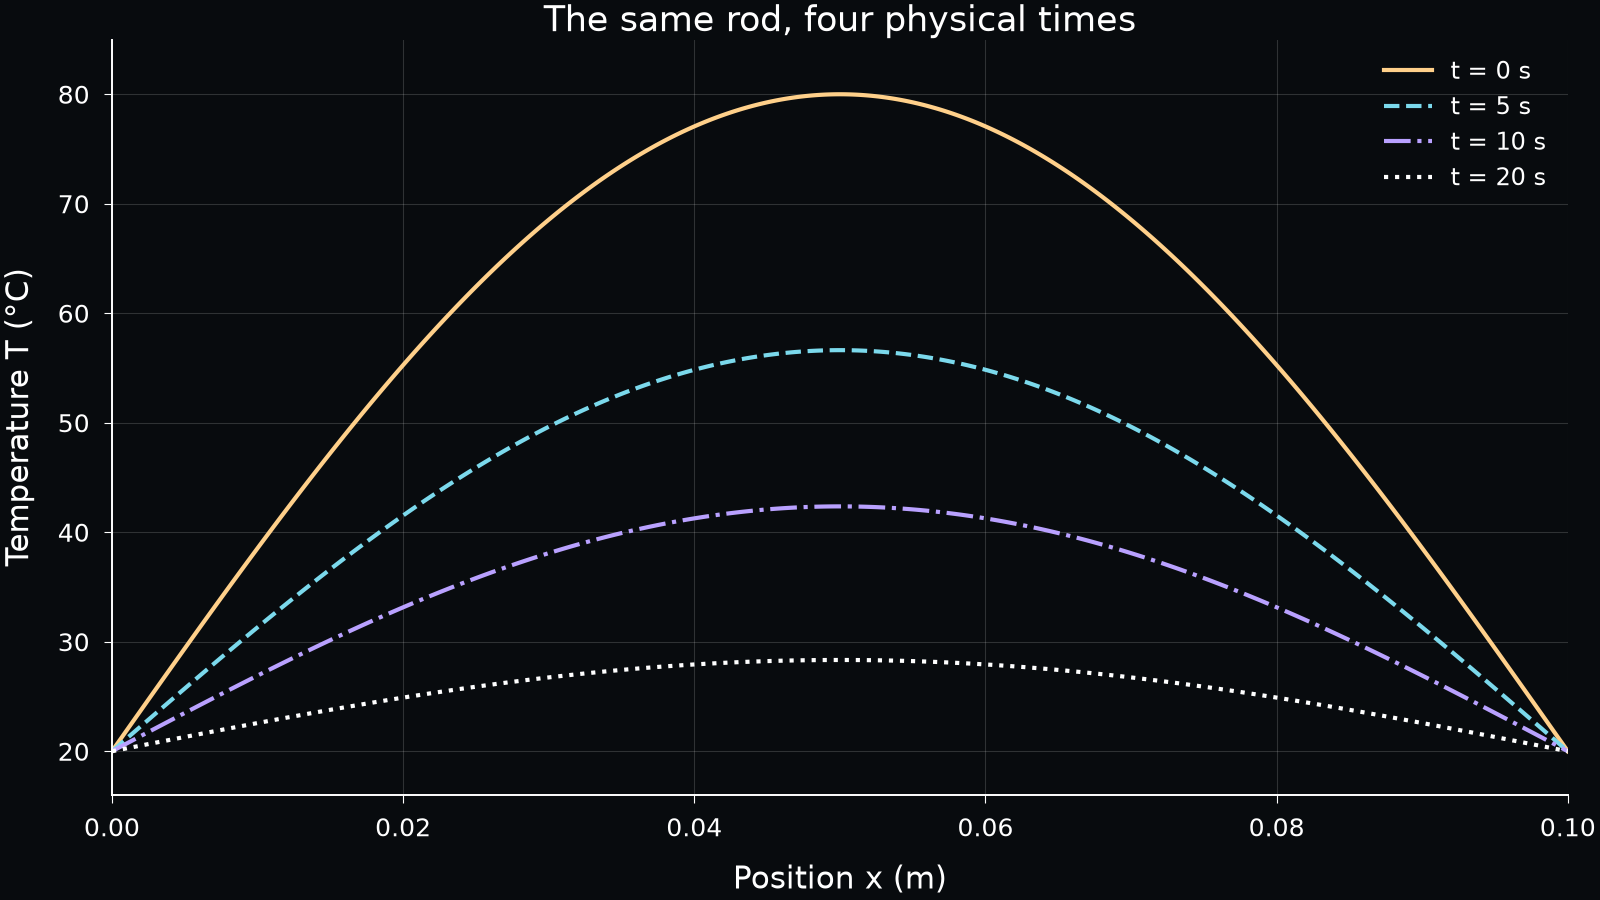

In [3]:
fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
selected_times_s = [0.0, 5.0, 10.0, 20.0]
for ts, color, line in zip(selected_times_s,
                          [AMBER, CYAN, VIOLET, '#FFFFFF'], ['-', '--', '-.', ':']):
    values = exact_temperature_C(x_m, ts)
    ax.plot(x_m, values, color=color, linestyle=line, label=f't = {ts:g} s')
ax.set(xlim=(0, L_M), ylim=(16, 85), xlabel='Position x (m)',
       ylabel='Temperature T (°C)', title='The same rod, four physical times')
style_axis(ax)
ax.legend(loc='upper right', frameon=False)
finish_figure(fig, '01_temperature_snapshots_4K.png',
              'Analytical temperature profiles at 0, 5, 10, and 20 seconds.')

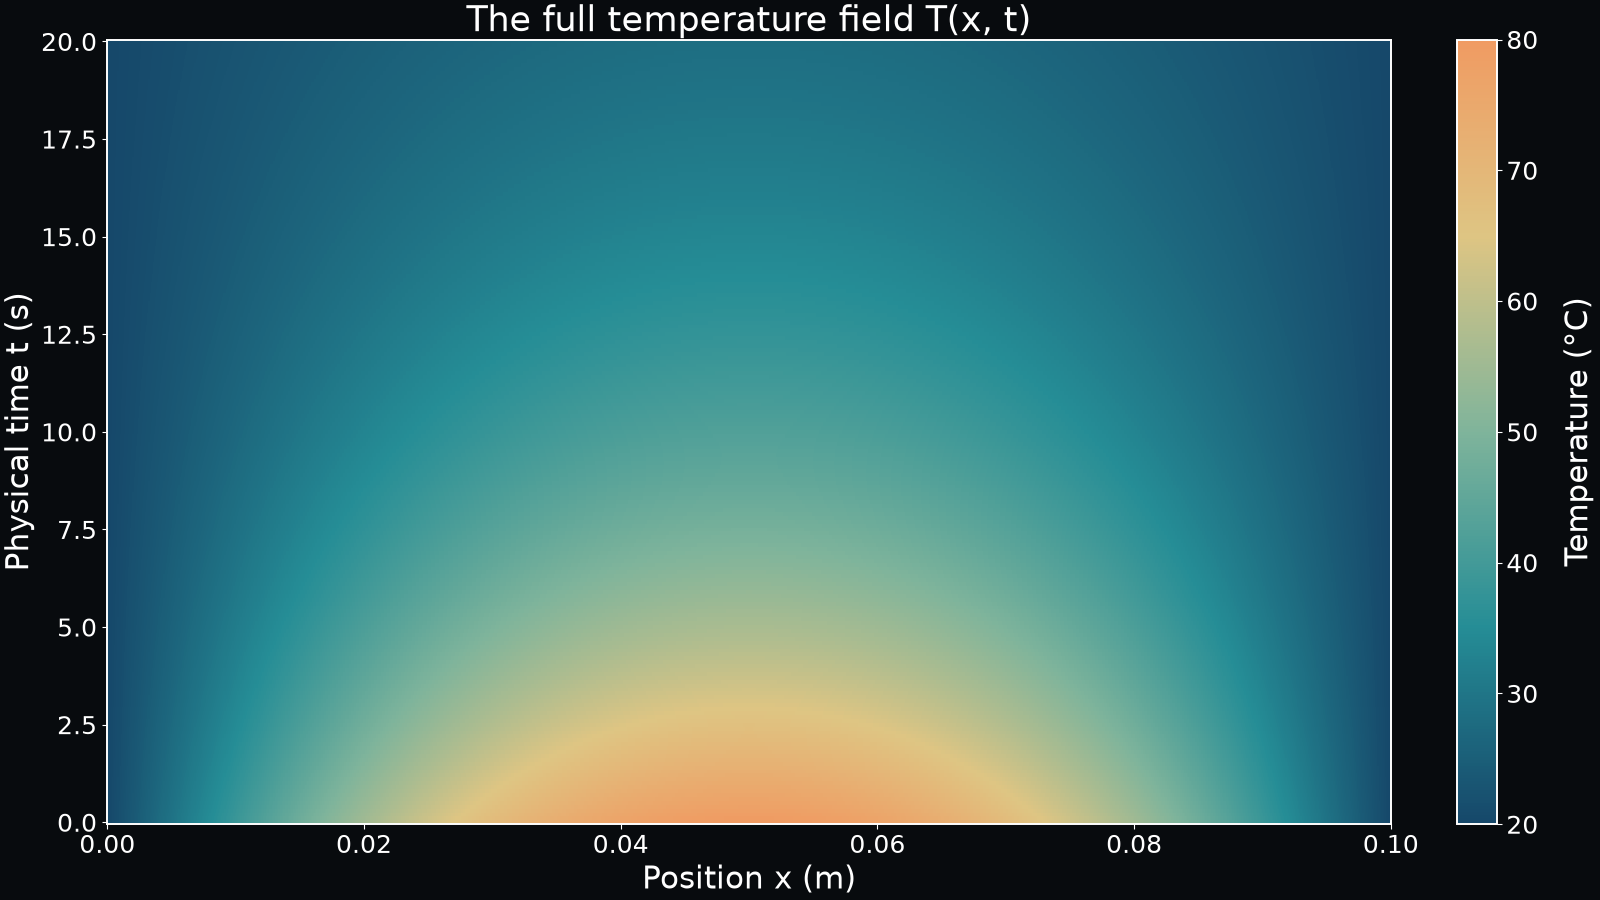

In [4]:
fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
im = ax.pcolormesh(x_m, t_s, EXACT_C, shading='auto', cmap=THERMAL, vmin=20, vmax=80)
ax.set(xlabel='Position x (m)', ylabel='Physical time t (s)',
       title='The full temperature field T(x, t)')
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label('Temperature (°C)', labelpad=18)
finish_figure(fig, '02_exact_spacetime_field_4K.png',
              'The analytical field; every pixel uses the time-by-position temperature array.')

**Read the figures:** the midpoint cools most visibly, while the endpoints remain at 20°C. The heatmap is a graph of temperature over position and time, not a photograph of the rod. These are analytical reference values, not measured predictive accuracy.

### 7. Generate five synthetic sensor observations
Put five virtual sensors strictly inside the rod at `k × L / 6`, for `k = 1, …, 5`. Their readings come directly from the exact formula with **no added measurement noise**. They are synthetic observations, not physical experimental measurements.

Virtual sensor     Position (m)     Synthetic T at 5 s (°C)
      1              0.016667            38.3149
      2              0.033333            51.7224
      3              0.050000            56.6299
      4              0.066667            51.7224
      5              0.083333            38.3149


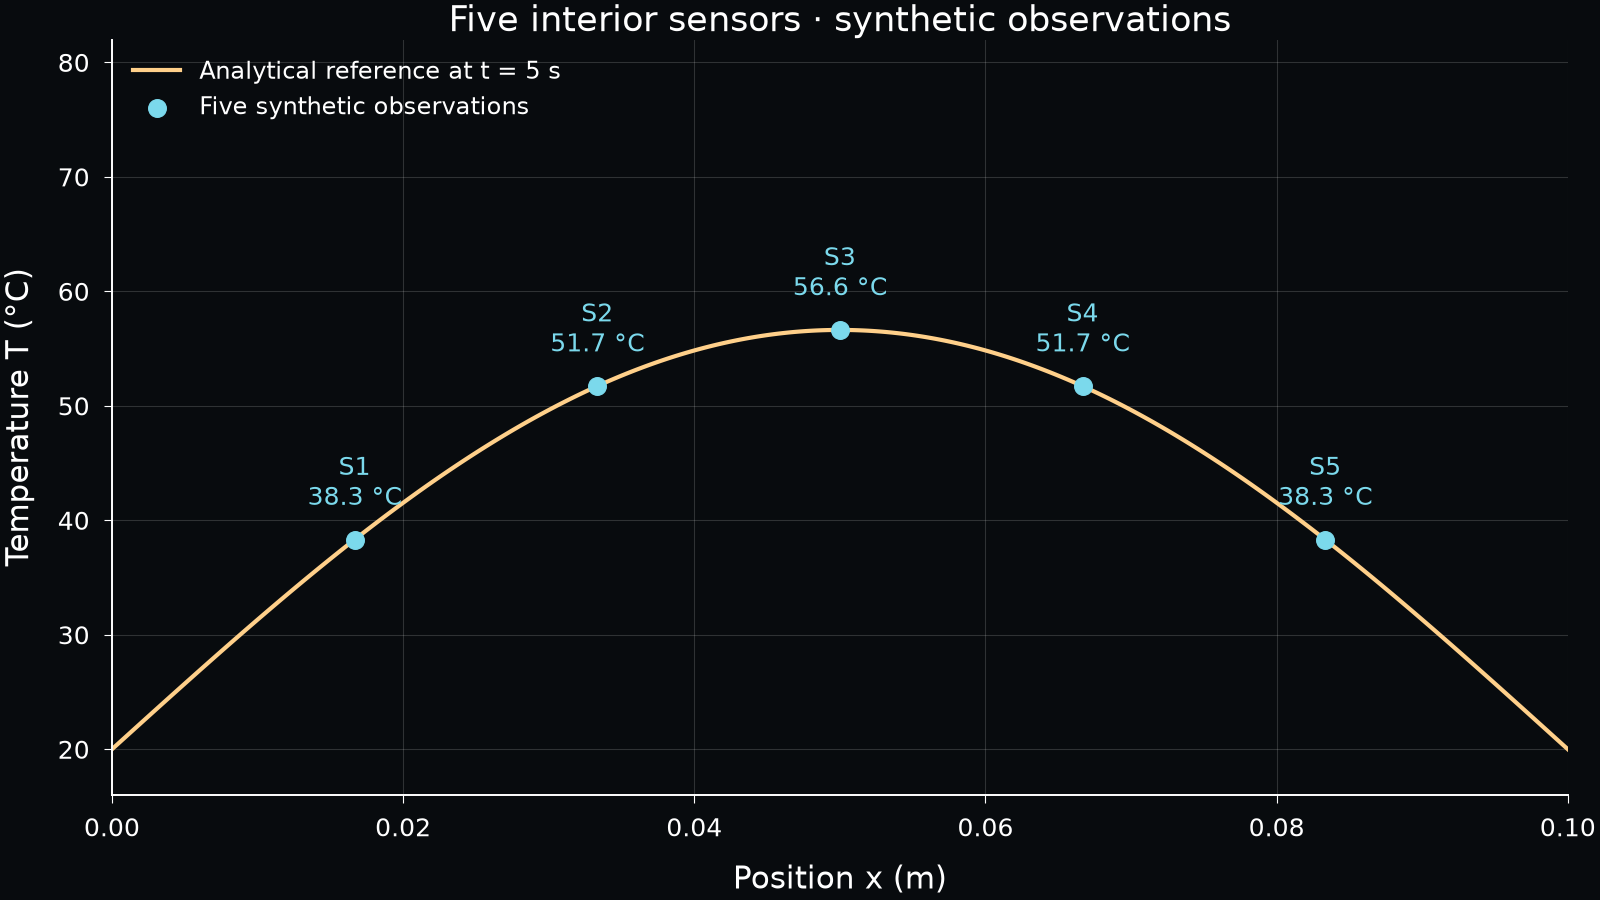

In [5]:
sensor_x_m = np.arange(1, 6, dtype=float) * L_M / 6.0
sensor_reference_C = exact_temperature_C(sensor_x_m[None, :], t_s[:, None])
SNAPSHOT_S = 5.0
sensor_snapshot_C = exact_temperature_C(sensor_x_m, SNAPSHOT_S)
print('Virtual sensor     Position (m)     Synthetic T at 5 s (°C)')
for i, (sx, temp) in enumerate(zip(sensor_x_m, sensor_snapshot_C), start=1):
    print(f'{i:^14d}     {sx:10.6f}          {temp:9.4f}')

fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
ax.plot(x_m, exact_temperature_C(x_m, SNAPSHOT_S), color=AMBER,
        label='Analytical reference at t = 5 s')
ax.scatter(sensor_x_m, sensor_snapshot_C, s=160, color=CYAN, zorder=4,
           label='Five synthetic observations')
for i, (sx, temp) in enumerate(zip(sensor_x_m, sensor_snapshot_C), start=1):
    ax.annotate(f'S{i}\n{temp:.1f} °C', (sx, temp), xytext=(0, 25),
                textcoords='offset points', ha='center', color=CYAN, fontsize=18)
ax.set(xlim=(0, L_M), ylim=(16, 82), xlabel='Position x (m)',
       ylabel='Temperature T (°C)', title='Five interior sensors · synthetic observations')
style_axis(ax)
ax.legend(loc='upper left', frameon=False)
finish_figure(fig, '03_five_synthetic_sensors_4K.png',
              'Five interior sensor positions and their computed reference readings at 5 seconds.')

### 8. Construct an illustrative candidate field
Add a deliberately chosen disturbance to the analytical reference:
$$\delta T(x,t)=A\sin(qx)g(t),\quad
q=\frac{6\pi}{L},\quad g(t)=1-e^{-t/\tau_c},\quad
A=10^\circ\mathrm{C},\quad \tau_c=5\,\mathrm{s}.$$
$$T_{\mathrm{candidate}}(x,t)=T_{\mathrm{exact}}(x,t)+\delta T(x,t).$$

This disturbance is invisible at the sensors: $qx_k=k\pi$ and $\sin(k\pi)=0$. It is also zero at both endpoints and at time zero.

Therefore the candidate matches **all five sensor time series**, the initial condition, and the endpoint conditions. This is an **analytically constructed counterexample**, not a trained neural-network prediction and not a physics-informed solution. Passing these particular checks is not enough to satisfy the PDE everywhere.

In [6]:
def added_temperature_C(x_m, t_s):
    return (COUNTEREXAMPLE_AMPLITUDE_C * np.sin(MODE_6_PER_M * np.asarray(x_m))
            * (-np.expm1(-np.asarray(t_s) / TAU_C_S)))

def candidate_temperature_C(x_m, t_s):
    return exact_temperature_C(x_m, t_s) + added_temperature_C(x_m, t_s)

CANDIDATE_C = candidate_temperature_C(X_M, TIME_S)
ERROR_C = CANDIDATE_C - EXACT_C
sensor_candidate_C = candidate_temperature_C(sensor_x_m[None, :], t_s[:, None])
assert CANDIDATE_C.shape == EXACT_C.shape == ERROR_C.shape
print(f'Maximum sensor difference over sampled times: '
      f'{np.max(np.abs(sensor_candidate_C - sensor_reference_C)):.3e} °C')
print(f'Maximum absolute field difference on this grid: {np.max(np.abs(ERROR_C)):.4f} °C')

Maximum sensor difference over sampled times: 2.487e-14 °C
Maximum absolute field difference on this grid: 9.8168 °C


### 9. Compare sensors with the space between them
At $t=5\,\mathrm{s}$ both curves pass through all five readings, but they disagree between readings. A signed error plot then shows where the candidate is warmer or cooler than the analytical reference.

The word **error** below means *candidate minus reference*, not a measured error of a trained model. The selected reference is known exactly in this demonstration.

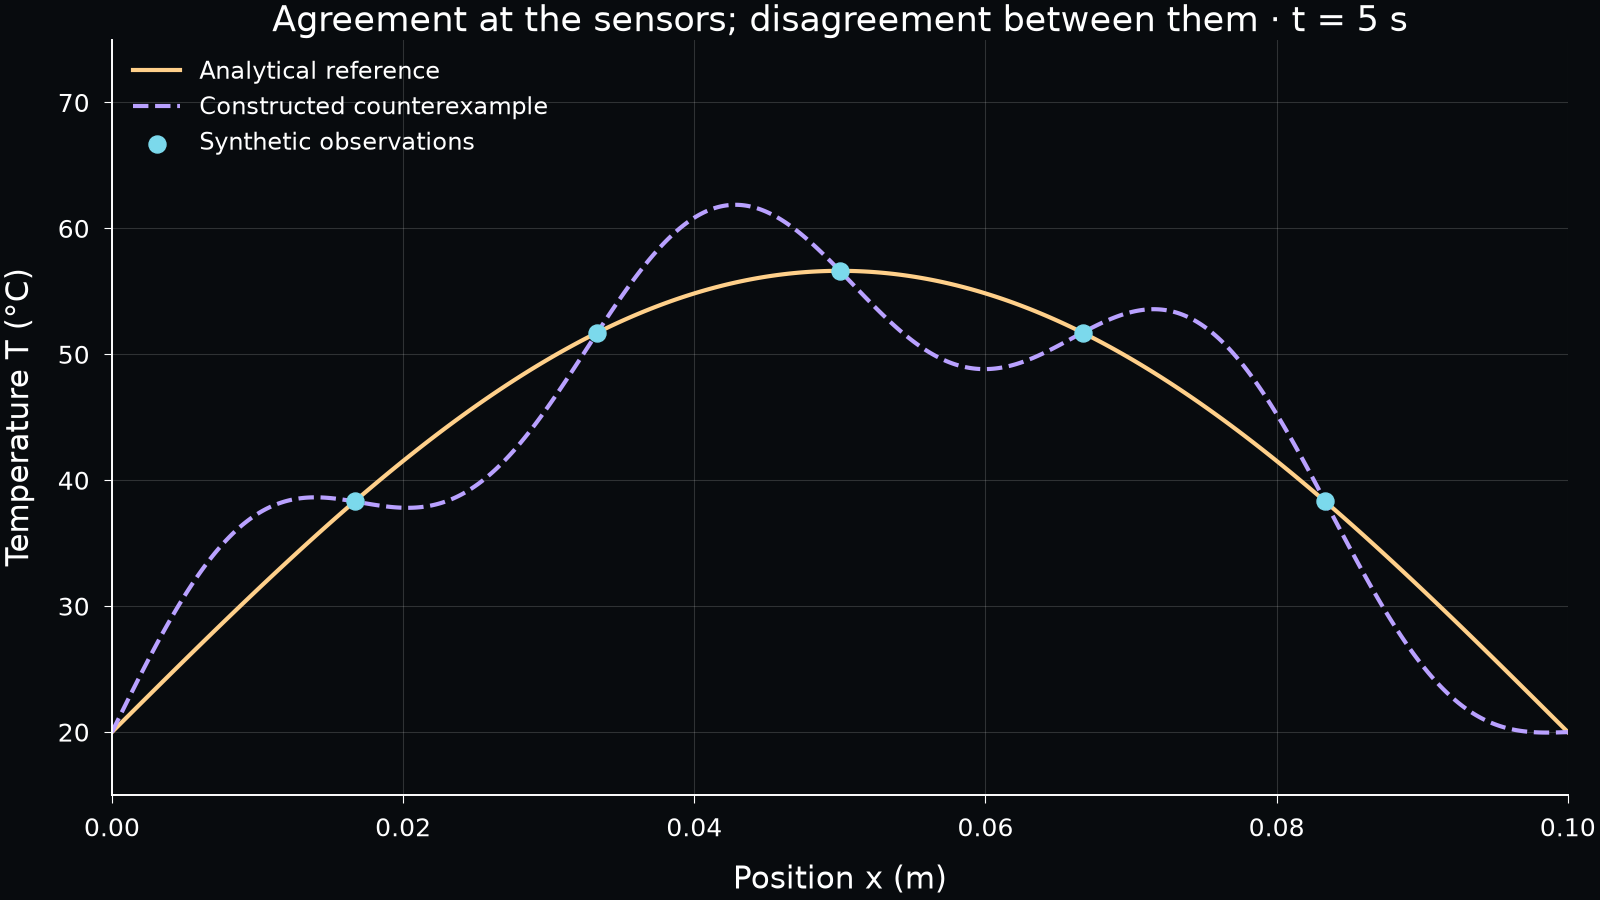

In [7]:
fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
ax.plot(x_m, exact_temperature_C(x_m, SNAPSHOT_S), color=AMBER, label='Analytical reference')
ax.plot(x_m, candidate_temperature_C(x_m, SNAPSHOT_S), color=VIOLET, linestyle='--',
        label='Constructed counterexample')
ax.scatter(sensor_x_m, sensor_snapshot_C, s=150, color=CYAN,
           label='Synthetic observations', zorder=5)
ax.set(xlim=(0, L_M), ylim=(15, 75), xlabel='Position x (m)',
       ylabel='Temperature T (°C)', title='Agreement at the sensors; disagreement between them · t = 5 s')
style_axis(ax)
ax.legend(loc='upper left', frameon=False)
finish_figure(fig, '04_reference_vs_counterexample_4K.png',
              'Both fields agree at the five synthetic observations but differ between them at 5 seconds.')

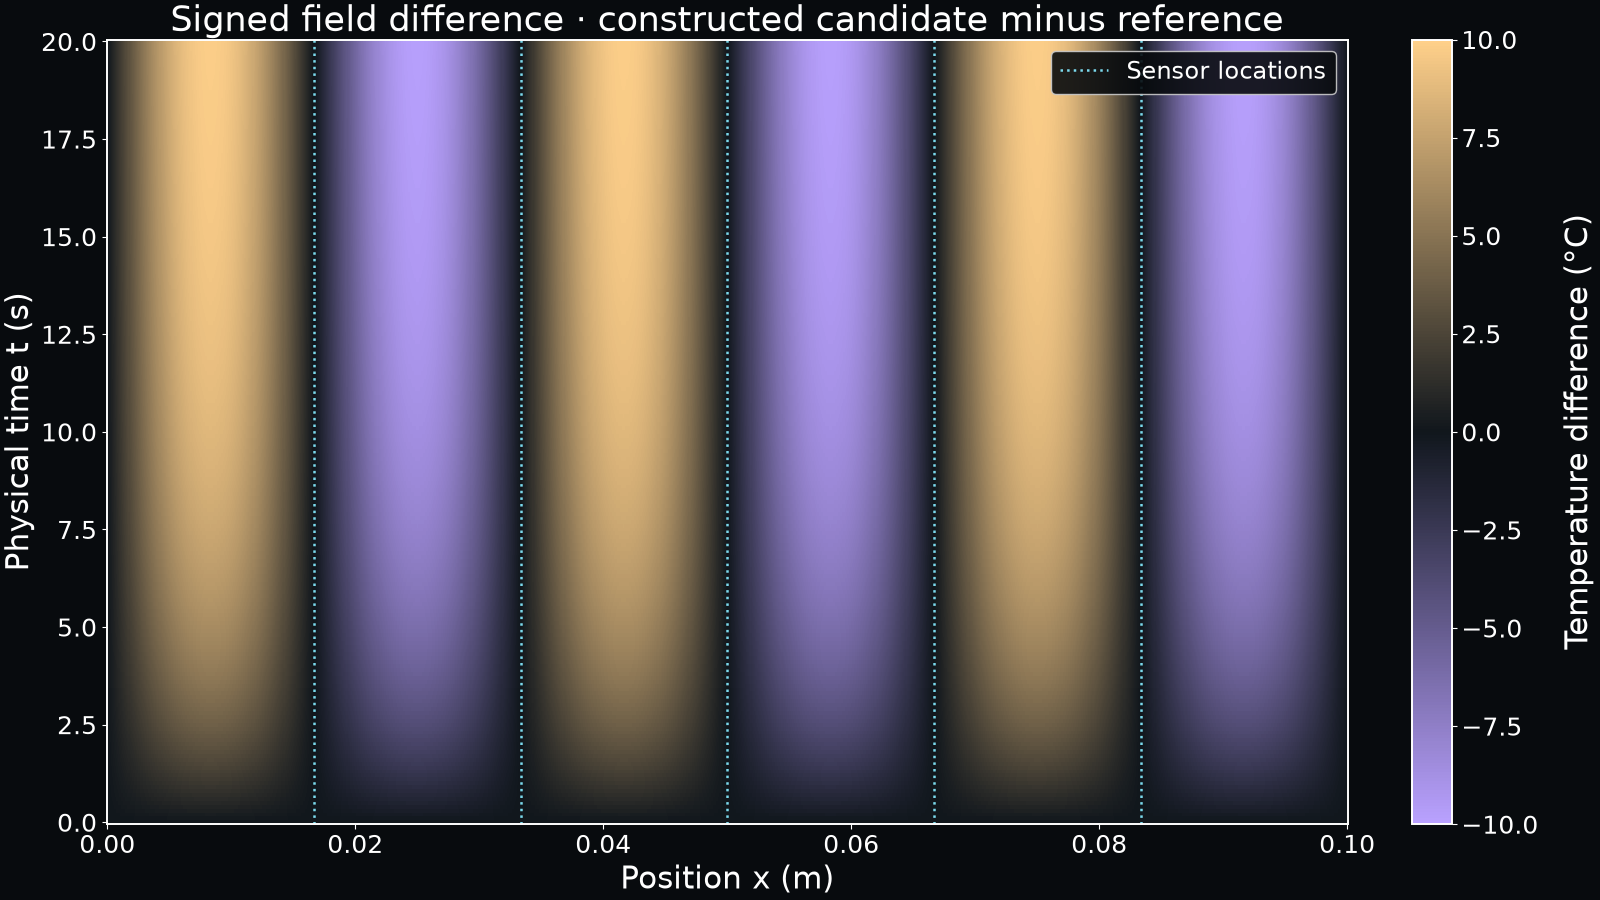

In [8]:
fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
im = ax.pcolormesh(x_m, t_s, ERROR_C, shading='auto', cmap=SIGNED,
                   vmin=-COUNTEREXAMPLE_AMPLITUDE_C, vmax=COUNTEREXAMPLE_AMPLITUDE_C)
for i, sx in enumerate(sensor_x_m):
    ax.axvline(sx, color=CYAN, linestyle=':', linewidth=1.8,
               label='Sensor locations' if i == 0 else None)
ax.set(xlabel='Position x (m)', ylabel='Physical time t (s)',
       title='Signed field difference · constructed candidate minus reference')
fig.colorbar(im, ax=ax, pad=0.03).set_label('Temperature difference (°C)', labelpad=18)
ax.legend(loc='upper right', facecolor=BG, framealpha=0.9)
finish_figure(fig, '05_signed_field_difference_4K.png',
              'Signed difference uses ERROR_C; dotted sensor lines coincide with zero disturbance.')

### 10. Derive and evaluate the heat-equation residual
Define a signed residual:
$$r[T]=T_t-\alpha T_{xx}.$$
A classical solution has $r[T]=0$ in the interior. Here a nonzero residual means failure to satisfy the stated source-free equation. A small residual at only a finite set of points is not a proof of a small solution error everywhere.

**Exact reference.** Write $k=\pi/L$ and $\beta=\alpha k^2$. Then
$$T_{\mathrm{exact},t}=-60\beta\sin(kx)e^{-\beta t},\quad
T_{\mathrm{exact},xx}=-60k^2\sin(kx)e^{-\beta t}.$$
Their contributions cancel identically.

**Added disturbance.** Differentiate its two factors separately:
$$\delta T_t=A\sin(qx)\frac{e^{-t/\tau_c}}{\tau_c},\qquad
\delta T_{xx}=-Aq^2\sin(qx)(1-e^{-t/\tau_c}).$$
Consequently,
$$\boxed{r[T_{\mathrm{candidate}}]
=A\sin(qx)\left[\frac{e^{-t/\tau_c}}{\tau_c}
+\alpha q^2(1-e^{-t/\tau_c})\right].}$$

**Sign and units:** the minus sign in $r=T_t-\alpha T_{xx}$ turns the negative spatial second derivative into a **plus** contribution. Both bracket terms have units $\mathrm{s^{-1}}$, so $r$ has units $^\circ\mathrm{C/s}$.

**Subtle point:** although $\delta T(x,0)=0$, its time derivative is generally not zero at $t=0$. Matching the initial temperature does not force the correct initial rate of change. We evaluate the PDE in the open time interval; the expression at zero describes its right-hand limit. The residual is also zero at every sensor, so checking the PDE only at these sensors would miss this counterexample.

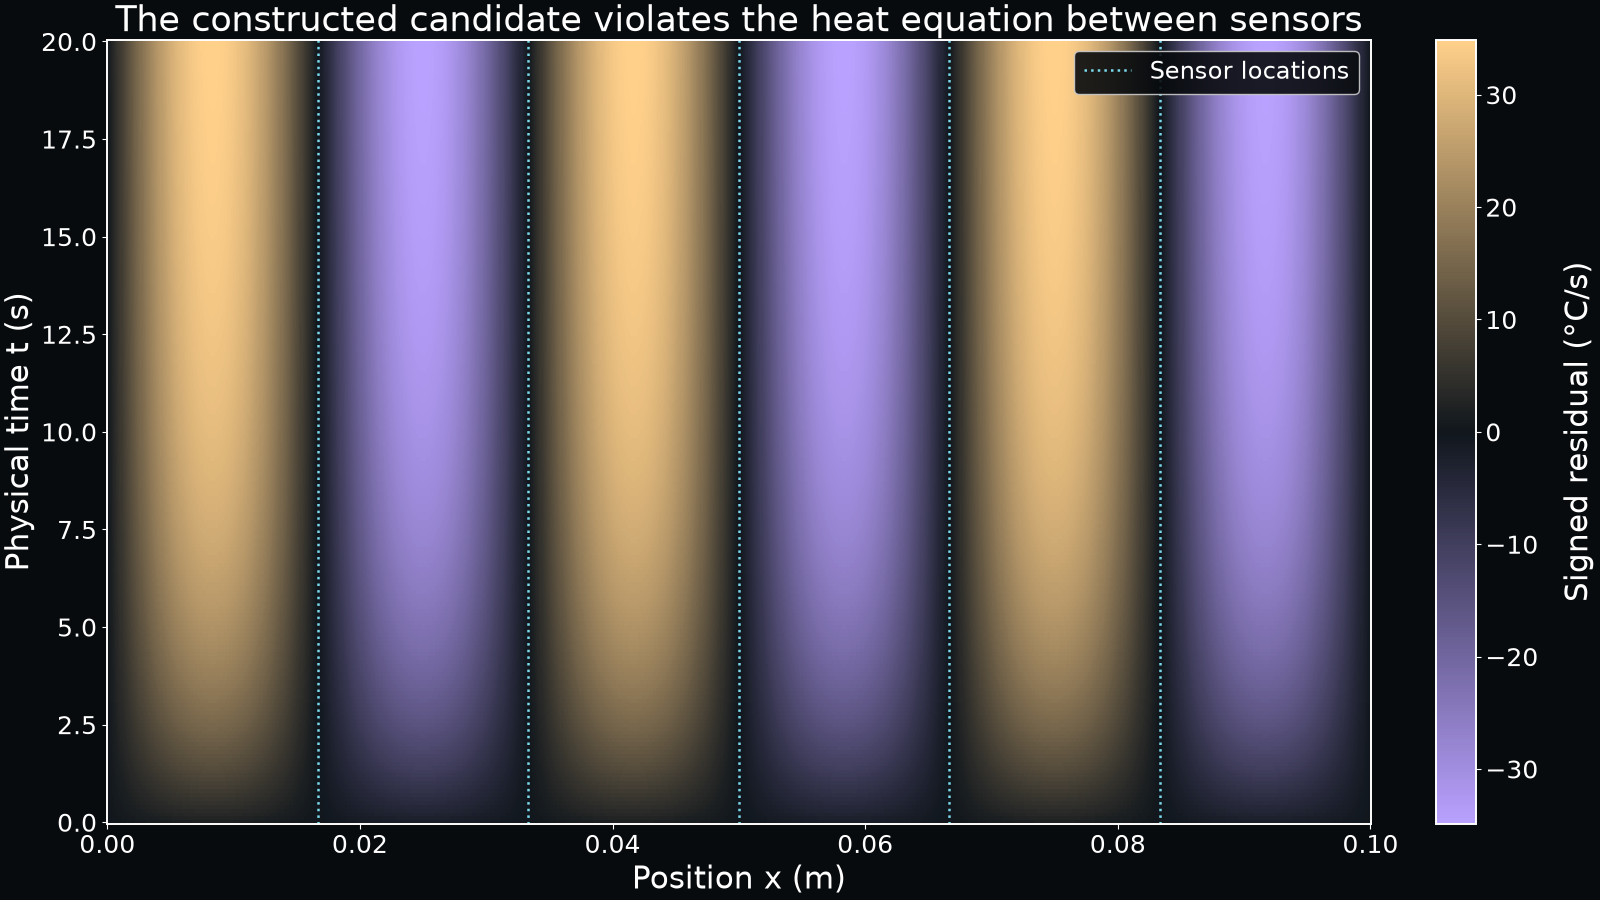

In [9]:
def candidate_residual_C_per_s(x_m, t_s):
    exponential = np.exp(-np.asarray(t_s) / TAU_C_S)
    return (COUNTEREXAMPLE_AMPLITUDE_C * np.sin(MODE_6_PER_M * np.asarray(x_m))
            * (exponential / TAU_C_S
               + ALPHA_M2_PER_S * MODE_6_PER_M**2 * (1.0 - exponential)))

RESIDUAL_C_PER_S = candidate_residual_C_per_s(X_M, TIME_S)
residual_limit = float(np.max(np.abs(RESIDUAL_C_PER_S)))
fig, ax = plt.subplots(figsize=(16, 9), layout='constrained')
im = ax.pcolormesh(x_m, t_s, RESIDUAL_C_PER_S, shading='auto', cmap=SIGNED,
                   vmin=-residual_limit, vmax=residual_limit)
for i, sx in enumerate(sensor_x_m):
    ax.axvline(sx, color=CYAN, linestyle=':', linewidth=1.8,
               label='Sensor locations' if i == 0 else None)
ax.set(xlabel='Position x (m)', ylabel='Physical time t (s)',
       title='The constructed candidate violates the heat equation between sensors')
fig.colorbar(im, ax=ax, pad=0.03).set_label('Signed residual (°C/s)', labelpad=18)
ax.legend(loc='upper right', facecolor=BG, framealpha=0.9)
finish_figure(fig, '06_candidate_pde_residual_4K.png',
              'Signed residual calculated from the derived expression; zero sensor residual hides off-sensor failure.')

### 11. Independently verify the mathematics and computation
We use three complementary checks:

1. **Identities:** evaluate initial conditions, boundary conditions, synthetic sensor agreement, symmetry of the reference, and cancellation of its analytical PDE derivatives.
2. **Independent numerical differentiation:** centered finite differences act on the *temperature functions*, without using the residual formula. We compare the result with the derived expression on interior test points, then halve both steps twice. Second-order differences should converge at approximately a factor of four until roundoff dominates. This is a verification calculation, not a trained-model accuracy benchmark.
3. **Export consistency:** reload the compact data and compare every exported field and all plotted sensor arrays to direct formula evaluation.

Temperature identity tolerance is $10^{-10}\,^\circ\mathrm C$; analytical residual tolerance is $10^{-10}\,^\circ\mathrm{C/s}$. Finite-difference tolerances are looser because derivatives are approximations. These tolerances are numerical verification choices, not physical measurement uncertainties.

In [10]:
CHECKS = {}
def require(name, condition):
    if not bool(condition):
        raise AssertionError(name)
    CHECKS[name] = 'PASS'

temp_tol = 1e-10
residual_tol = 1e-10
initial_C = BASE_C + INITIAL_AMPLITUDE_C * np.sin(MODE_1_PER_M * x_m)
require('exact_initial_condition', np.allclose(exact_temperature_C(x_m, 0), initial_C, atol=temp_tol, rtol=0))
require('candidate_initial_condition', np.allclose(candidate_temperature_C(x_m, 0), initial_C, atol=temp_tol, rtol=0))
for name, field in [('exact', exact_temperature_C), ('candidate', candidate_temperature_C)]:
    for endpoint_name, endpoint in [('left', 0.0), ('right', L_M)]:
        require(name + '_' + endpoint_name + '_boundary',
                np.allclose(field(endpoint, t_s), BASE_C, atol=temp_tol, rtol=0))
require('sensor_positions_strictly_interior', np.all((sensor_x_m > 0) & (sensor_x_m < L_M)))
require('five_sensor_time_series_agree', np.allclose(sensor_candidate_C, sensor_reference_C, atol=temp_tol, rtol=0))
require('exact_reference_symmetry', np.allclose(EXACT_C, EXACT_C[:, ::-1], atol=temp_tol, rtol=0))
require('exact_reference_temperature_bounds', np.min(EXACT_C) >= 20 - temp_tol and np.max(EXACT_C) <= 80 + temp_tol)
require('midpoint_still_above_boundary_at_20s', 28.33 < exact_temperature_C(L_M / 2, END_S) < 28.34)

exact_t_C_per_s = (-INITIAL_AMPLITUDE_C * DECAY_PER_S * np.sin(MODE_1_PER_M * X_M)
                   * np.exp(-DECAY_PER_S * TIME_S))
exact_xx_C_per_m2 = (-INITIAL_AMPLITUDE_C * MODE_1_PER_M**2 * np.sin(MODE_1_PER_M * X_M)
                     * np.exp(-DECAY_PER_S * TIME_S))
exact_analytic_residual = exact_t_C_per_s - ALPHA_M2_PER_S * exact_xx_C_per_m2
require('exact_analytical_pde_cancellation', np.max(np.abs(exact_analytic_residual)) < residual_tol)

# Interior points chosen independently of the export grid and sensors.
test_x_m = np.linspace(0.0031, 0.0967, 71)
test_t_s = np.linspace(0.37, 19.63, 39)
TEST_X, TEST_T = np.meshgrid(test_x_m, test_t_s)
def finite_difference_residual(field, x, t, dx, dt):
    time_derivative = (field(x, t + dt) - field(x, t - dt)) / (2 * dt)
    curvature = (field(x + dx, t) - 2 * field(x, t) + field(x - dx, t)) / dx**2
    return time_derivative - ALPHA_M2_PER_S * curvature

fd_candidate_errors = []
fd_exact_errors = []
for subdivisions, dt in [(400, 0.02), (800, 0.01), (1600, 0.005)]:
    dx = L_M / subdivisions
    fd_candidate = finite_difference_residual(candidate_temperature_C, TEST_X, TEST_T, dx, dt)
    fd_exact = finite_difference_residual(exact_temperature_C, TEST_X, TEST_T, dx, dt)
    fd_candidate_errors.append(float(np.max(np.abs(fd_candidate - candidate_residual_C_per_s(TEST_X, TEST_T)))))
    fd_exact_errors.append(float(np.max(np.abs(fd_exact))))
convergence_ratios = np.array(fd_candidate_errors[:-1]) / np.array(fd_candidate_errors[1:])
require('candidate_residual_independent_finite_differences', fd_candidate_errors[-1] < 0.002)
require('candidate_residual_second_order_convergence', np.all((convergence_ratios > 3.7) & (convergence_ratios < 4.3)))
require('exact_residual_independent_finite_differences', fd_exact_errors[-1] < 1e-5)
require('exact_residual_refines_toward_zero', fd_exact_errors[2] < fd_exact_errors[1] < fd_exact_errors[0])

off_sensor_x_m = L_M / 12.0  # sin(q*x) = 1, halfway between the left end and sensor 1.
off_sensor_t_s = 5.0
off_sensor_residual = float(candidate_residual_C_per_s(off_sensor_x_m, off_sensor_t_s))
off_sensor_error = float(added_temperature_C(off_sensor_x_m, off_sensor_t_s))
require('candidate_nonzero_off_sensor_residual', off_sensor_residual > 20.0)
require('candidate_residual_sign_at_positive_sine', off_sensor_residual > 0)
require('candidate_residual_sign_at_negative_sine', candidate_residual_C_per_s(L_M / 4, 5.0) < 0)
require('candidate_residual_zero_at_sensors', np.max(np.abs(candidate_residual_C_per_s(sensor_x_m[None, :], t_s[:, None]))) < residual_tol)
require('initial_disturbance_zero_but_rate_nonzero', abs(added_temperature_C(off_sensor_x_m, 0.0)) < temp_tol
        and np.isclose(candidate_residual_C_per_s(off_sensor_x_m, 0), COUNTEREXAMPLE_AMPLITUDE_C / TAU_C_S))

print('Independent finite-difference verification (maximum absolute error, °C/s)')
print('dx (m)       dt (s)       Exact residual       Candidate residual discrepancy')
for n, dt, e0, ec in zip([400, 800, 1600], [0.02, 0.01, 0.005], fd_exact_errors, fd_candidate_errors):
    print(f'{L_M/n:.7f}    {dt:.3f}        {e0:.3e}             {ec:.3e}')
print('Candidate discrepancy refinement ratios:', np.round(convergence_ratios, 4))
print(f'At x = L/12 and t = 5 s: difference = {off_sensor_error:.6f} °C; residual = {off_sensor_residual:.6f} °C/s')

Independent finite-difference verification (maximum absolute error, °C/s)
dx (m)       dt (s)       Exact residual       Candidate residual discrepancy
0.0002500    0.020        3.306e-05             6.445e-03
0.0001250    0.010        8.264e-06             1.611e-03
0.0000625    0.005        2.066e-06             4.028e-04
Candidate discrepancy refinement ratios: [3.9998 3.9999]
At x = L/12 and t = 5 s: difference = 6.321206 °C; residual = 23.195366 °C/s


#### See the contrast without mixing units
The left panel shows temperature agreement at one sensor and disagreement at a nearby point. The right panel shows the PDE residual at those same two positions. The quantities use separate axes because a temperature difference and a PDE residual have different units.

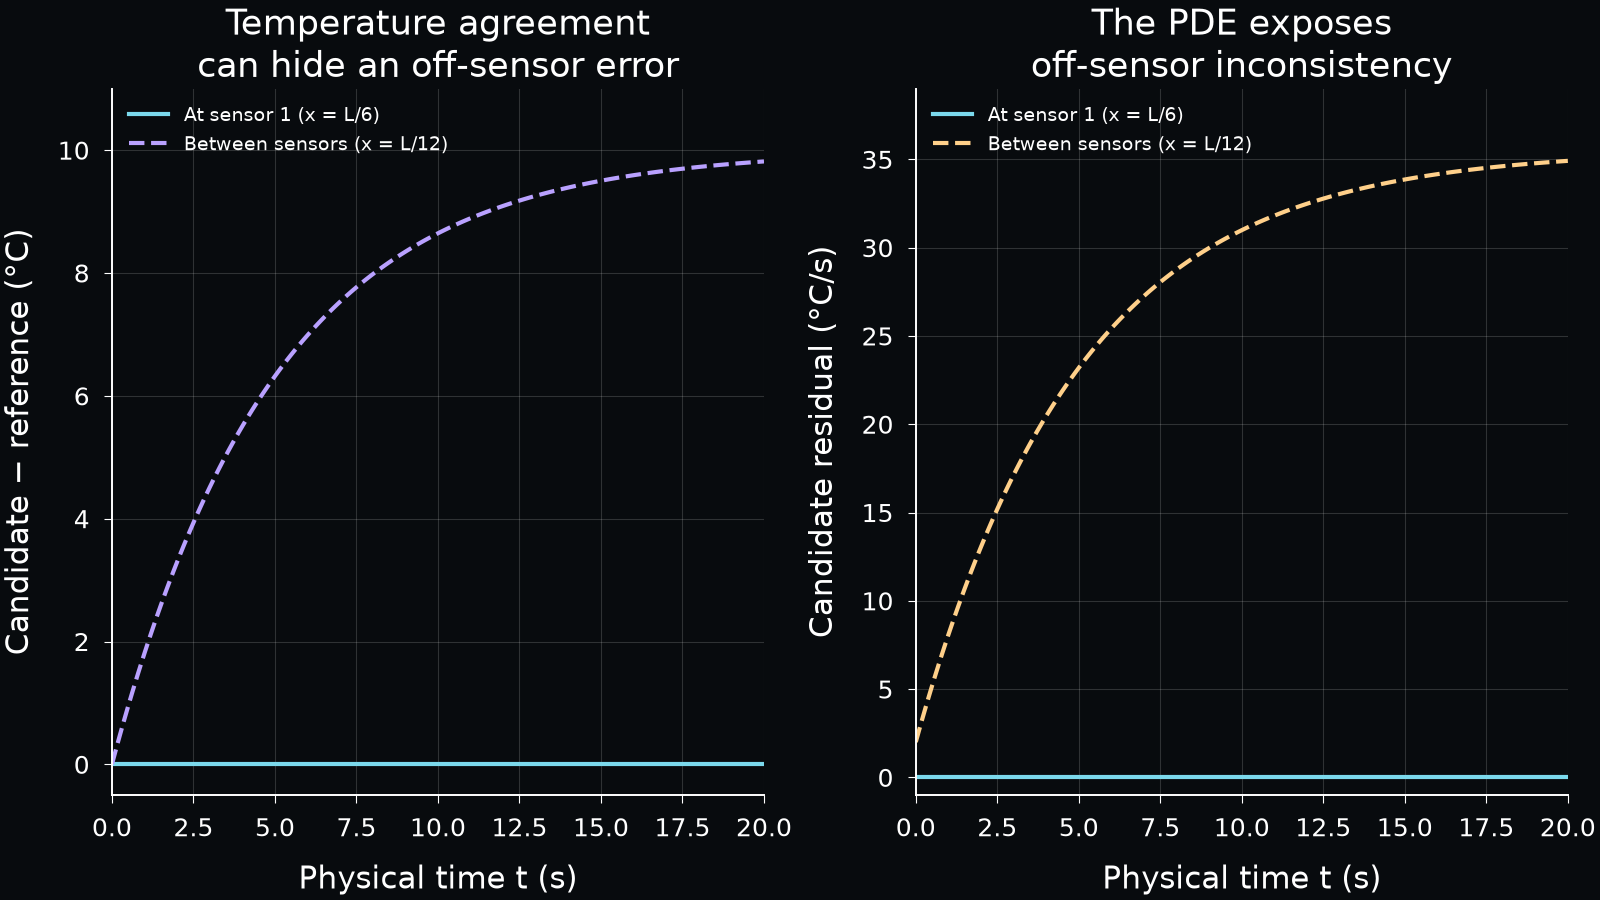

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), layout='constrained')
sensor_error_series_C = sensor_candidate_C[:, 0] - sensor_reference_C[:, 0]
off_error_series_C = added_temperature_C(off_sensor_x_m, t_s)
sensor_residual_series = candidate_residual_C_per_s(sensor_x_m[0], t_s)
off_residual_series = candidate_residual_C_per_s(off_sensor_x_m, t_s)
axes[0].plot(t_s, sensor_error_series_C, color=CYAN, label='At sensor 1 (x = L/6)')
axes[0].plot(t_s, off_error_series_C, color=VIOLET, linestyle='--', label='Between sensors (x = L/12)')
axes[0].set(title='Temperature agreement\ncan hide an off-sensor error', xlabel='Physical time t (s)',
            ylabel='Candidate − reference (°C)', xlim=(0, END_S), ylim=(-0.5, 11))
axes[1].plot(t_s, sensor_residual_series, color=CYAN, label='At sensor 1 (x = L/6)')
axes[1].plot(t_s, off_residual_series, color=AMBER, linestyle='--', label='Between sensors (x = L/12)')
axes[1].set(title='The PDE exposes\noff-sensor inconsistency', xlabel='Physical time t (s)',
            ylabel='Candidate residual (°C/s)', xlim=(0, END_S), ylim=(-1, 39))
for ax in axes:
    style_axis(ax)
    ax.legend(loc='upper left', fontsize=14, frameon=False)
finish_figure(fig, '07_sensor_vs_off_sensor_checks_4K.png',
              'Separate panels compare temperature differences and PDE residuals at a sensor and an off-sensor point.')

#### Export the checked numerical arrays
This compact file contains numerical values suitable for scientific reference plots or a separate ManimGL scene. It is not a rendered video. The metadata records units and the array orientation. Figure 07's displayed series are exported explicitly as well.

In [12]:
data_path = DATA / 'EP01_heat_equation_verified_arrays.npz'
metadata = {'array_orientation': 'field[time_index, position_index]',
    'temperature_units': 'degree Celsius', 'position_units': 'm', 'time_units': 's',
    'residual_units': 'degree Celsius / s', 'synthetic_observations': True,
    'candidate_kind': 'analytically constructed counterexample; not trained',
    'parameters': {'L_m': L_M, 'alpha_m2_per_s': ALPHA_M2_PER_S,
                   'baseline_C': BASE_C, 'initial_amplitude_C': INITIAL_AMPLITUDE_C,
                   'counterexample_amplitude_C': COUNTEREXAMPLE_AMPLITUDE_C, 'tau_c_s': TAU_C_S}}
np.savez_compressed(data_path, x_m=x_m, t_s=t_s, exact_C=EXACT_C, candidate_C=CANDIDATE_C,
    error_C=ERROR_C, candidate_residual_C_per_s=RESIDUAL_C_PER_S,
    sensor_x_m=sensor_x_m, sensor_reference_C=sensor_reference_C,
    sensor_candidate_C=sensor_candidate_C, selected_times_s=np.array(selected_times_s),
    snapshot_s=np.array(SNAPSHOT_S), sensor_snapshot_C=sensor_snapshot_C,
    off_sensor_x_m=np.array(off_sensor_x_m), sensor_error_series_C=sensor_error_series_C,
    off_error_series_C=off_error_series_C, sensor_residual_series_C_per_s=sensor_residual_series,
    off_residual_series_C_per_s=off_residual_series,
    metadata_json=np.array(json.dumps(metadata)))

with np.load(data_path, allow_pickle=False) as saved:
    saved_X, saved_T = np.meshgrid(saved['x_m'], saved['t_s'])
    require('export_exact_array_consistency', np.array_equal(saved['exact_C'], exact_temperature_C(saved_X, saved_T)))
    require('export_candidate_array_consistency', np.array_equal(saved['candidate_C'], candidate_temperature_C(saved_X, saved_T)))
    require('export_error_array_consistency', np.array_equal(saved['error_C'], saved['candidate_C'] - saved['exact_C']))
    require('export_residual_array_consistency', np.array_equal(saved['candidate_residual_C_per_s'], candidate_residual_C_per_s(saved_X, saved_T)))
    require('export_sensor_array_consistency', np.array_equal(saved['sensor_reference_C'], exact_temperature_C(saved['sensor_x_m'][None, :], saved['t_s'][:, None])))
    require('export_snapshot_array_consistency', np.array_equal(saved['sensor_snapshot_C'], exact_temperature_C(saved['sensor_x_m'], float(saved['snapshot_s']))))
    require('export_comparison_series_consistency',
            np.array_equal(saved['sensor_error_series_C'], saved['sensor_candidate_C'][:, 0] - saved['sensor_reference_C'][:, 0])
            and np.array_equal(saved['off_error_series_C'], added_temperature_C(float(saved['off_sensor_x_m']), saved['t_s']))
            and np.array_equal(saved['off_residual_series_C_per_s'], candidate_residual_C_per_s(float(saved['off_sensor_x_m']), saved['t_s']))
            and np.array_equal(saved['sensor_residual_series_C_per_s'], candidate_residual_C_per_s(float(saved['sensor_x_m'][0]), saved['t_s'])))

require('seven_figure_exports_exist', len(FIGURE_MANIFEST) == 7 and all((ROOT / f['file']).is_file() for f in FIGURE_MANIFEST))
metrics = {
    'max_sensor_difference_C': float(np.max(np.abs(sensor_candidate_C - sensor_reference_C))),
    'max_field_difference_C_on_export_grid': float(np.max(np.abs(ERROR_C))),
    'max_candidate_residual_C_per_s_on_export_grid': residual_limit,
    'max_exact_analytic_residual_C_per_s': float(np.max(np.abs(exact_analytic_residual))),
    'midpoint_temperature_at_20s_C': float(exact_temperature_C(L_M/2, END_S)),
    'off_sensor_at_L_over_12_t5s_difference_C': off_sensor_error,
    'off_sensor_at_L_over_12_t5s_residual_C_per_s': off_sensor_residual,
    'finite_difference_candidate_errors_C_per_s': fd_candidate_errors,
    'finite_difference_exact_errors_C_per_s': fd_exact_errors,
    'finite_difference_candidate_refinement_ratios': convergence_ratios.tolist(),
}
report = {'generated_utc': datetime.now(timezone.utc).isoformat(),
          'execution': 'All notebook verification cells executed in this runtime',
          'versions': VERSIONS, 'checks': CHECKS, 'metrics': metrics,
          'figures': FIGURE_MANIFEST, 'data': metadata,
          'data_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest()}
(ROOT / 'verification_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
print(f'{len(CHECKS)} / {len(CHECKS)} checks PASS. Seven 4K figures exported.')
print('Compact numerical data:', data_path.name)

29 / 29 checks PASS. Seven 4K figures exported.
Compact numerical data: EP01_heat_equation_verified_arrays.npz


### 12. Interpretation and limits
**What the counterexample establishes:** these five noiseless sensor time series, together with the stated initial and boundary temperatures, do not by themselves force an arbitrary smooth candidate to satisfy the governing PDE. The disturbance was chosen specifically to be invisible at those sensors.

**Why there is no contradiction with uniqueness:** for this well-posed heat problem, the PDE, initial condition, and boundary conditions together select the analytical solution. Our candidate is excluded because it violates the PDE. The example is not claiming multiple solutions of that full problem.

**What it does not establish:** this is not evidence about the performance, training speed, data efficiency, or superiority of a particular PIML/PINN method. There is no optimization, learned parameter, train/test split, or neural-network result here. The residual is computed from known smooth formulas. Real data may be noisy, physics may be approximate, and derivatives may be difficult to estimate.

**Independent checks matter:** locations used only for fitting or tuning are not independent validation evidence. Here we use off-sensor locations to expose a constructed inconsistency and a known exact solution to verify the code. In a real prediction task, validation needs suitable evidence not reused to tune the model. A residual has different units from a temperature error; their magnitudes should not be equated.

**A useful caution:** the residual vanishes even at the five sensors. Adding a physics check at exactly those same locations would still miss the failure. Sampling the domain and validating the result require care; finite sampled residuals are not a universal guarantee.

In [13]:
display(Markdown(
    f'**Executed result.** At all five sensors, the largest sampled temperature difference is '
    f'**{metrics["max_sensor_difference_C"]:.2e} °C** (floating-point roundoff). '
    f'At $x=L/12$, $t=5$ s, the difference is **{off_sensor_error:.3f} °C** '
    f'and the heat-equation residual is **{off_sensor_residual:.3f} °C/s**. '
    f'All **{len(CHECKS)}** explicit verification checks passed.'))

**Executed result.** At all five sensors, the largest sampled temperature difference is **2.49e-14 °C** (floating-point roundoff). At $x=L/12$, $t=5$ s, the difference is **6.321 °C** and the heat-equation residual is **23.195 °C/s**. All **29** explicit verification checks passed.

### 13. Try it yourself
Run the notebook once before experimenting. Keep the verified version as a baseline.

1. **Predict, then inspect.** At $x=L/12$, will the candidate be warmer or cooler than the reference at 5 seconds? Identify the sign of $\sin(6\pi x/L)$, then evaluate `added_temperature_C(L_M/12, 5.0)`.
2. **Move one sensor.** Evaluate the difference at `x = L_M/12` over `t_s`. Compare it with the reading at `L_M/6`. Explain why the additional sensor detects the disturbance. Do not alter the five baseline sensors merely to make their agreement test pass.
3. **Change the amplitude in a copy.** Replace $A=10$ with $A=5$ and rerun the calculation cells. Predict how the field difference and residual scale. Tests with fixed illustrative thresholds, such as `residual > 20`, refer to the baseline experiment; adjust an exercise copy's thresholds with a mathematical reason, not just to hide a failure.
4. **Design another invisible mode.** For $N$ equally spaced interior sensors at $kL/(N+1)$, consider a disturbance proportional to $\sin((N+1)\pi x/L)g(t)$. Show why it vanishes at those sensors. How does increasing the spatial frequency affect the second derivative?
5. **Explain the distinction.** In two sentences, explain why zero sensor error is not the same as zero PDE residual, and why a small residual at a finite set of locations does not prove the entire solution is accurate.

<details><summary>Check your reasoning after attempting the exercises</summary>

1. At $x=L/12$, the sine equals $+1$, so the candidate is warmer for $t>0$.
2. The new location lies at a disturbance antinode; the old sensor lies at a node.
3. Both the disturbance and its residual scale linearly with $A$. The reference does not change.
4. At a sensor the sine argument is $k\pi$. The curvature contribution scales with the square of the frequency.
5. Observations constrain values at selected locations; a PDE also constrains derivatives. Independent validation must check the relevant physical behavior beyond the fitting evidence.

</details>

### 14. Connect the experiment to PIML and PINNs
Physics-informed machine learning uses physical knowledge to guide learning or prediction. This can be introduced through model structure, constraints, losses, or combinations of those choices. It is a broader approach than any one neural-network method.

In a common PINN formulation, a neural function represents a candidate field, derivatives are calculated, and training penalizes violations of the supplied governing equation and suitable data or conditions. Other formulations can enforce some constraints by construction. The formula we constructed here is **not a PINN**; it explains why physical constraints can add information beyond fitting observations.

The next conceptual lesson maps SciML, PIML, and PINNs. Later lessons build the mathematical and computational tools; the first full PINN training lesson is **EP11**. Useful prediction still needs appropriate assumptions, careful training, and independent validation. Physical information does not automatically guarantee accuracy, speed, or superiority over established solvers.

**Takeaway:** fitting the available observations is one check. Satisfying the stated physics is another. Trust requires evidence for the claim being made.

#### References and provenance
- G. E. Karniadakis et al., *Physics-informed machine learning*, Nature Reviews Physics **3**, 422–440 (2021). [DOI: 10.1038/s42254-021-00314-5](https://doi.org/10.1038/s42254-021-00314-5). General PIML context; the counterexample in this notebook is a pedagogical construction, not a reported result from that review.
- M. Raissi, P. Perdikaris, and G. E. Karniadakis: [author-maintained PINNs project](https://maziarraissi.github.io/PINNs/). Primary explanation of the differential-equation residual and representative PINN formulations.
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html): notebook upload, execution, and sharing.
- Course alignment: Hyper Technology, *70-Episode Master Curriculum v1.1 — Final Production Blueprint — 2026*. The physical reference matches the EP01 scientific benchmark; sensor layout and the added disturbance are explicitly defined in this lab.


## Episode Video

Watch the course on the [official Hyper Technology YouTube channel](https://www.youtube.com/@hypertechnology4273). The direct EP01 video link will be added after the episode is published.

[Official course repository](https://github.com/Mo88maher/Hyper-Technology-PIML-Course) · [Course index](../../README.md)
